In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import geobr
from pathlib import Path

PROCESSED_DIR = Path("../../data/processed")
df_solo = pd.read_parquet(PROCESSED_DIR / "solo_microrregioes_limpo.parquet")

# 1. Padroniza o CD_MICRO para string
df_solo['CD_MICRO'] = df_solo['CD_MICRO'].astype(float).astype(int).astype(str)

# 2. CONVERSÃO DE UNIDADES DO SOILGRIDS
# pH: O SoilGrids multiplica por 10. Vamos dividir para ter o pH real.
cols_ph = [c for c in df_solo.columns if 'phh2o' in c]
df_solo[cols_ph] = df_solo[cols_ph] / 10.0

# Argila, Areia, Silte: vêm em g/kg (ex: 300). Vamos transformar em % dividindo por 10.
cols_textura = [c for c in df_solo.columns if any(x in c for x in ['clay', 'sand', 'silt'])]
df_solo[cols_textura] = df_solo[cols_textura] / 10.0

# 3. Carrega o mapa e faz o merge
gdf_micro = geobr.read_micro_region(year=2020)
gdf_micro['code_micro'] = gdf_micro['code_micro'].astype(int).astype(str)

gdf_plot = gdf_micro.merge(df_solo, left_on='code_micro', right_on='CD_MICRO', how='left')

print("Dados preparados e convertidos para unidades reais (pH, % de textura).")
print(f"Shape da base: {df_solo.shape}")

microregions_2020_simplified.parquet: 100%|██████████| 7.91M/7.91M [00:00<00:00, 15.4MB/s]


Dados preparados e convertidos para unidades reais (pH, % de textura).
Shape da base: (558, 25)


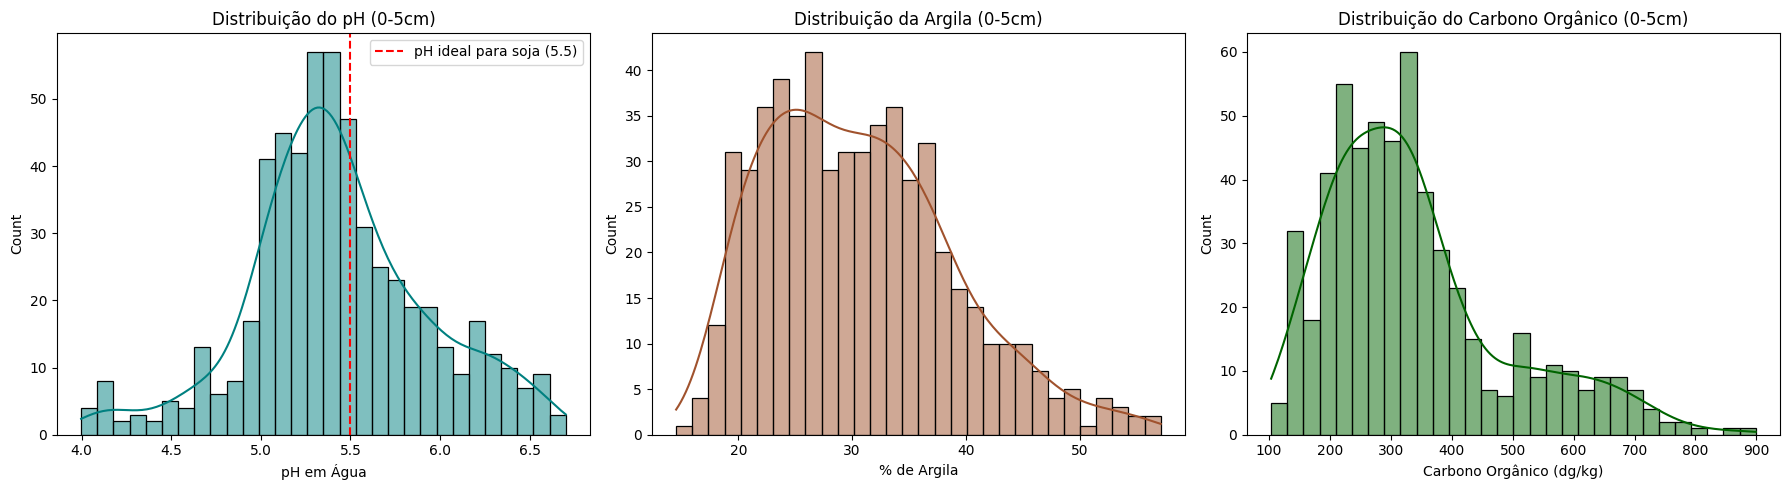

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histograma de pH (0-5cm)
sns.histplot(df_solo['phh2o_0-5cm_mean'].dropna(), bins=30, kde=True, ax=axes[0], color='teal')
axes[0].set_title('Distribuição do pH (0-5cm)')
axes[0].set_xlabel('pH em Água')
axes[0].axvline(5.5, color='red', linestyle='--', label='pH ideal para soja (5.5)')
axes[0].legend()

# Histograma de Argila (0-5cm)
sns.histplot(df_solo['clay_0-5cm_mean'].dropna(), bins=30, kde=True, ax=axes[1], color='sienna')
axes[1].set_title('Distribuição da Argila (0-5cm)')
axes[1].set_xlabel('% de Argila')

# Histograma de Carbono Orgânico (0-5cm)
sns.histplot(df_solo['soc_0-5cm_mean'].dropna(), bins=30, kde=True, ax=axes[2], color='darkgreen')
axes[2].set_title('Distribuição do Carbono Orgânico (0-5cm)')
axes[2].set_xlabel('Carbono Orgânico (dg/kg)')

plt.tight_layout()
plt.show()

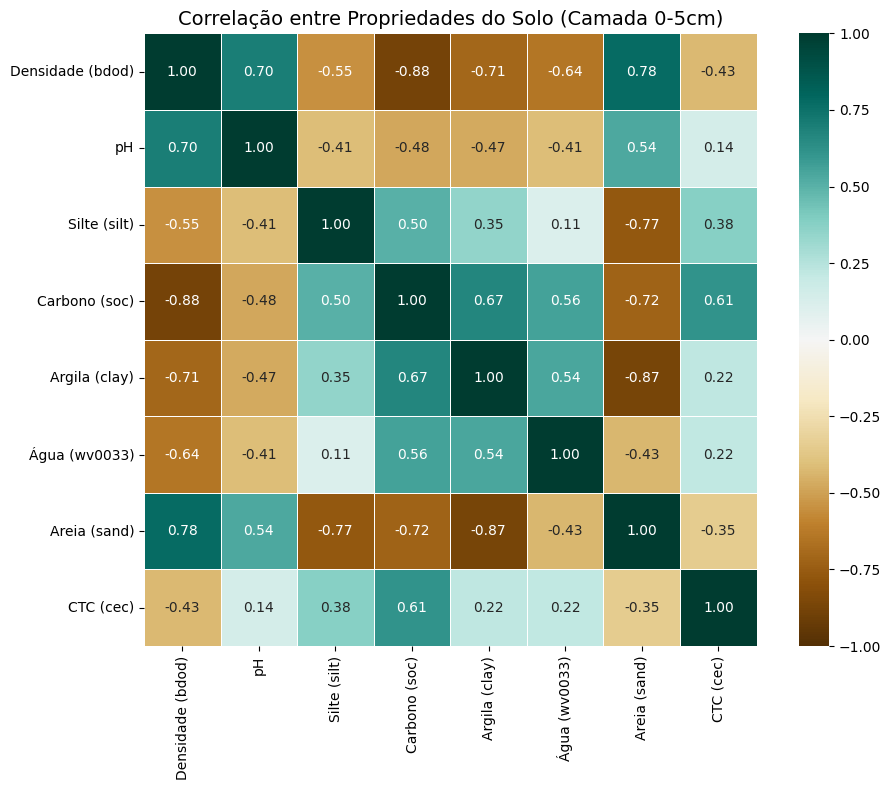

In [3]:
# Seleciona apenas as variáveis da camada 0-5cm
cols_05cm = [c for c in df_solo.columns if '0-5cm' in c]
corr_05cm = df_solo[cols_05cm].corr()

# Renomeia as colunas para ficarem legíveis no gráfico
nomes_limpos = {
    'bdod_0-5cm_mean': 'Densidade (bdod)',
    'cec_0-5cm_mean': 'CTC (cec)',
    'clay_0-5cm_mean': 'Argila (clay)',
    'phh2o_0-5cm_mean': 'pH',
    'sand_0-5cm_mean': 'Areia (sand)',
    'silt_0-5cm_mean': 'Silte (silt)',
    'soc_0-5cm_mean': 'Carbono (soc)',
    'wv0033_0-5cm_mean': 'Água (wv0033)'
}
corr_05cm = corr_05cm.rename(index=nomes_limpos, columns=nomes_limpos)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_05cm, annot=True, fmt=".2f", cmap='BrBG', vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Correlação entre Propriedades do Solo (Camada 0-5cm)', fontsize=14)
plt.tight_layout()
plt.show()

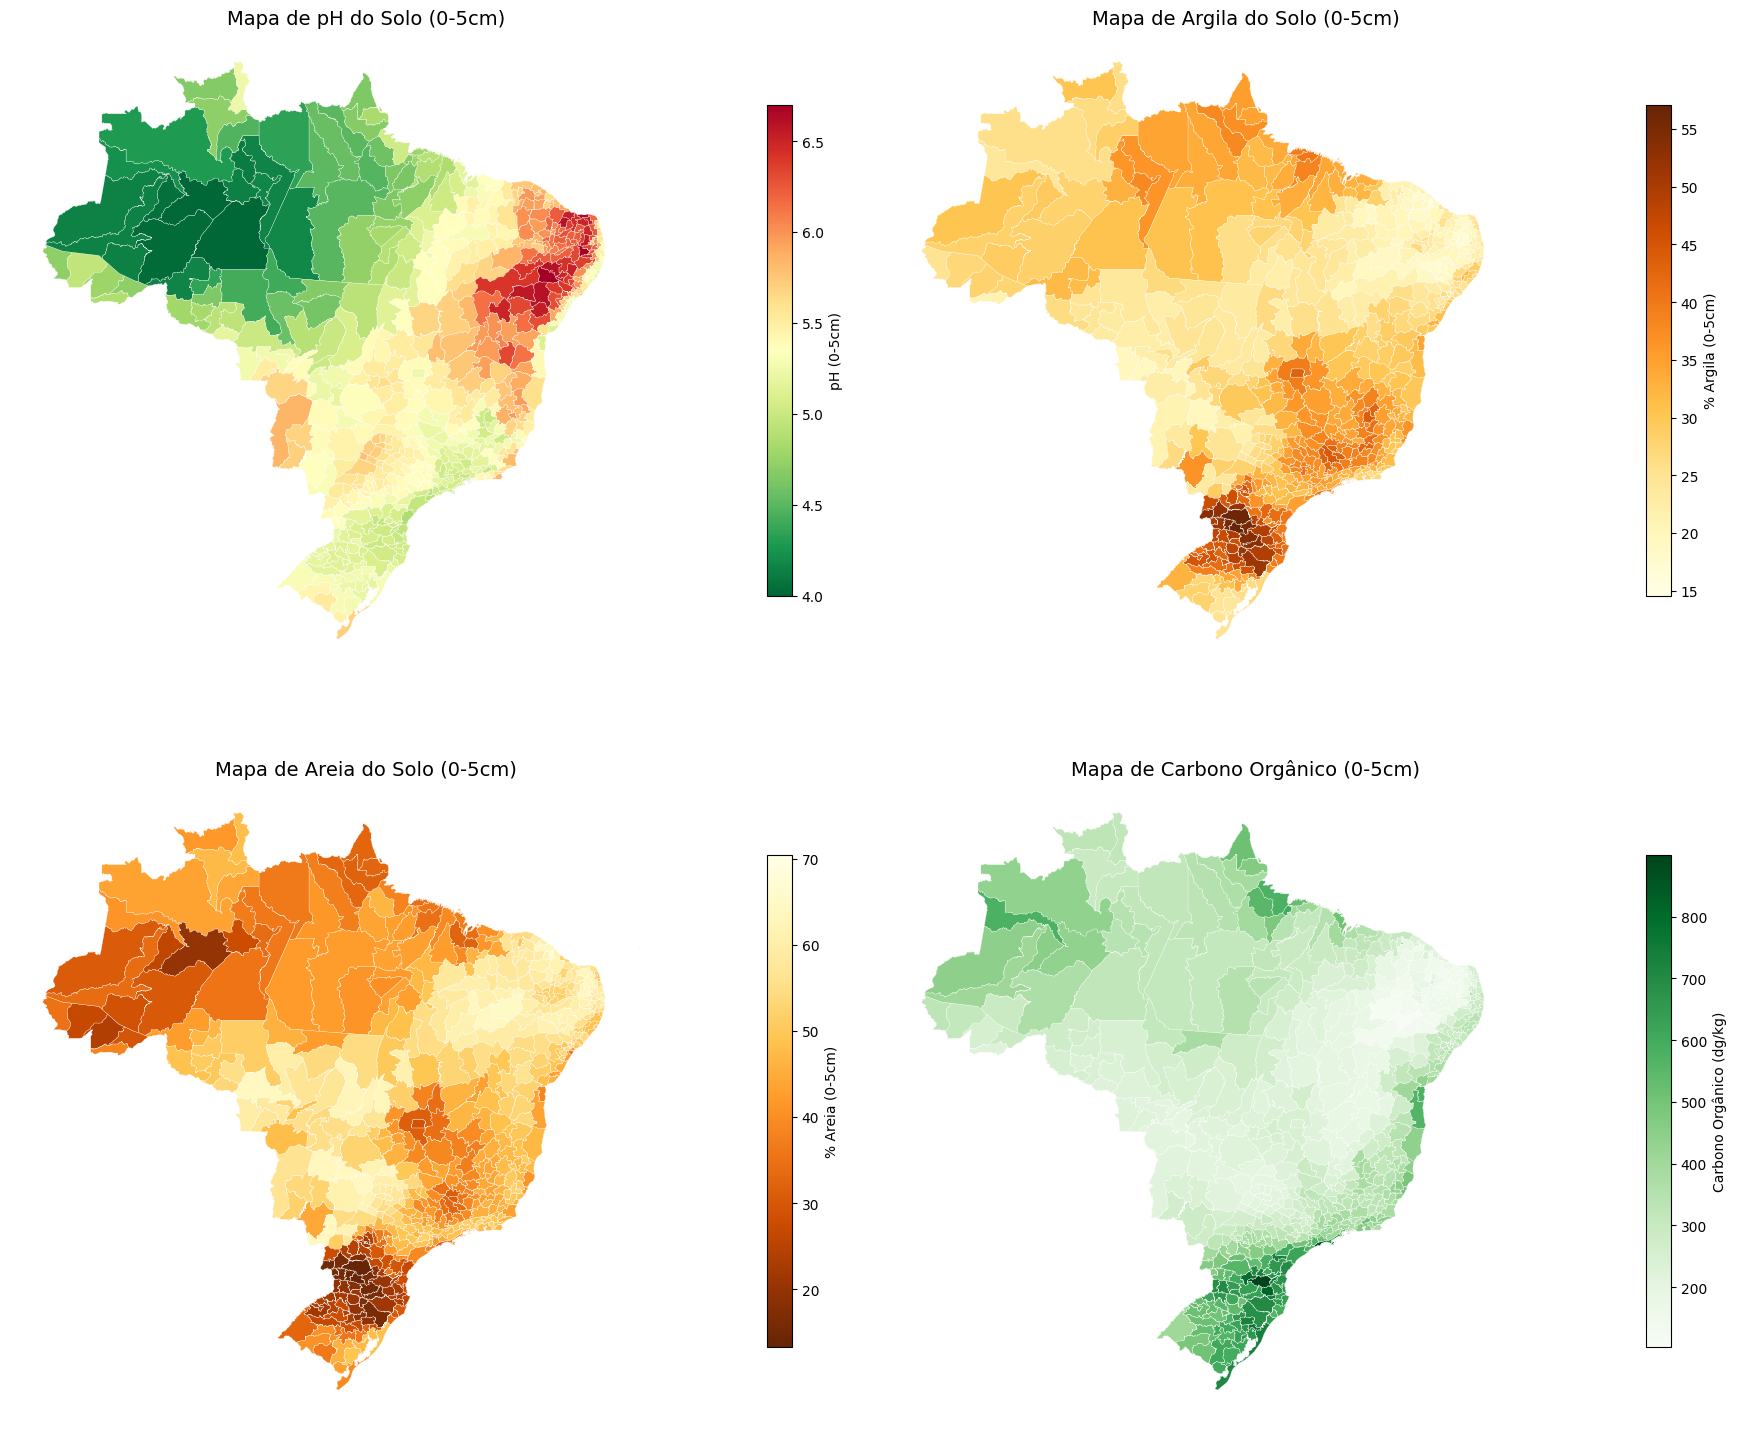

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(18, 16))
axes = axes.flatten()

# 1. Mapa de pH
gdf_plot.plot(column='phh2o_0-5cm_mean', cmap='RdYlGn_r', legend=True, 
              legend_kwds={'label': 'pH (0-5cm)', 'shrink': 0.6}, ax=axes[0], edgecolor='white', linewidth=0.2)
axes[0].set_title('Mapa de pH do Solo (0-5cm)', fontsize=14)
axes[0].axis('off')

# 2. Mapa de Argila
gdf_plot.plot(column='clay_0-5cm_mean', cmap='YlOrBr', legend=True, 
              legend_kwds={'label': '% Argila (0-5cm)', 'shrink': 0.6}, ax=axes[1], edgecolor='white', linewidth=0.2)
axes[1].set_title('Mapa de Argila do Solo (0-5cm)', fontsize=14)
axes[1].axis('off')

# 3. Mapa de Areia
gdf_plot.plot(column='sand_0-5cm_mean', cmap='YlOrBr_r', legend=True, 
              legend_kwds={'label': '% Areia (0-5cm)', 'shrink': 0.6}, ax=axes[2], edgecolor='white', linewidth=0.2)
axes[2].set_title('Mapa de Areia do Solo (0-5cm)', fontsize=14)
axes[2].axis('off')

# 4. Mapa de Carbono Orgânico
gdf_plot.plot(column='soc_0-5cm_mean', cmap='Greens', legend=True, 
              legend_kwds={'label': 'Carbono Orgânico (dg/kg)', 'shrink': 0.6}, ax=axes[3], edgecolor='white', linewidth=0.2)
axes[3].set_title('Mapa de Carbono Orgânico (0-5cm)', fontsize=14)
axes[3].axis('off')

plt.tight_layout()
plt.show()

Contagem de microrregiões por região:
Regiao
Nordeste        188
Sudeste         160
Sul              94
Norte            64
Centro-Oeste     52
Name: count, dtype: int64


/var/folders/j3/kppygfjs7xj9nbzbwjj9cjc80000gn/T/ipykernel_73217/3419638615.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=gdf_plot_regioes, x='Regiao', y='phh2o_0-5cm_mean', ax=axes[0], palette="Set2")
/var/folders/j3/kppygfjs7xj9nbzbwjj9cjc80000gn/T/ipykernel_73217/3419638615.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=gdf_plot_regioes, x='Regiao', y='clay_0-5cm_mean', ax=axes[1], palette="Set2")


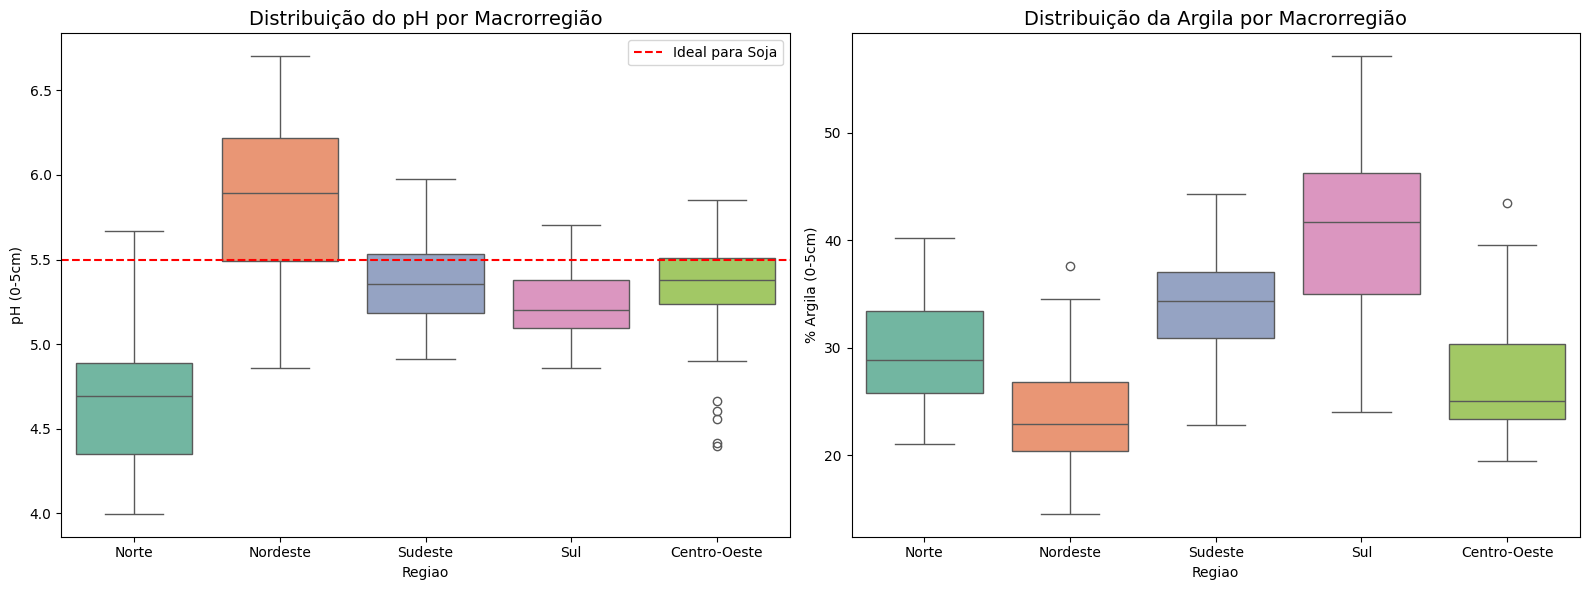

In [6]:
# Adiciona a região do Brasil (Norte, Nordeste, Sudeste, Sul, Centro-Oeste)
# O code_region no geobr vem como inteiro, mas às vezes pode vir como float ou string. Vamos padronizar.
gdf_plot['code_region'] = gdf_plot['code_region'].astype(float).astype(int).astype(str)

mapa_regioes = {'1': 'Norte', '2': 'Nordeste', '3': 'Sudeste', '4': 'Sul', '5': 'Centro-Oeste'}
gdf_plot['Regiao'] = gdf_plot['code_region'].map(mapa_regioes)

# Remove linhas onde a Regiao é nula para não quebrar o plot
gdf_plot_regioes = gdf_plot.dropna(subset=['Regiao']).copy()

print("Contagem de microrregiões por região:")
print(gdf_plot_regioes['Regiao'].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot de pH por Região
sns.boxplot(data=gdf_plot_regioes, x='Regiao', y='phh2o_0-5cm_mean', ax=axes[0], palette="Set2")
axes[0].set_title('Distribuição do pH por Macrorregião', fontsize=14)
axes[0].set_ylabel('pH (0-5cm)')
axes[0].axhline(5.5, color='red', linestyle='--', label='Ideal para Soja')
axes[0].legend()

# Boxplot de Argila por Região
sns.boxplot(data=gdf_plot_regioes, x='Regiao', y='clay_0-5cm_mean', ax=axes[1], palette="Set2")
axes[1].set_title('Distribuição da Argila por Macrorregião', fontsize=14)
axes[1].set_ylabel('% Argila (0-5cm)')

plt.tight_layout()
plt.show()